In [185]:
# Maternal Health Risk Prediction using KNN

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import joblib

# Load the dataset
dataset = pd.read_csv("Maternal Health Risk Data Set.csv")

In [186]:
# Display dataset
dataset


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk
...,...,...,...,...,...,...,...
1009,22,120,60,15.0,98.0,80,high risk
1010,55,120,90,18.0,98.0,60,high risk
1011,35,85,60,19.0,98.0,86,high risk
1012,43,120,90,18.0,98.0,70,high risk


In [187]:
# Dataset information
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


In [188]:
# Statistical summary
dataset.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,29.871795,113.198225,76.460552,8.725986,98.665089,74.301775
std,13.474386,18.403913,13.885796,3.293532,1.371384,8.088702
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,100.000000,65.000000,6.900000,98.000000,70.000000
50%,26.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,39.000000,120.000000,90.000000,8.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


In [189]:
# Check value counts of target variable
dataset['RiskLevel'].value_counts()

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

In [190]:
# Let us do preprocessing
#let us convert string to int

mapping={
    'low risk': 0,
    'mid risk': 1,
    'high risk': 2
}
dataset['RiskLevel']=dataset['RiskLevel'].map(mapping)


In [191]:
# Let us extract x,y
x=dataset.drop('RiskLevel', axis=1)
y=dataset['RiskLevel']



In [192]:
# Check first row of features
x

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
0,25,130,80,15.0,98.0,86
1,35,140,90,13.0,98.0,70
2,29,90,70,8.0,100.0,80
3,30,140,85,7.0,98.0,70
4,35,120,60,6.1,98.0,76
...,...,...,...,...,...,...
1009,22,120,60,15.0,98.0,80
1010,55,120,90,18.0,98.0,60
1011,35,85,60,19.0,98.0,86
1012,43,120,90,18.0,98.0,70


In [193]:
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   int64  
dtypes: float64(2), int64(5)
memory usage: 55.6 KB


In [194]:
import seaborn as sns


<Axes: xlabel='count', ylabel='RiskLevel'>

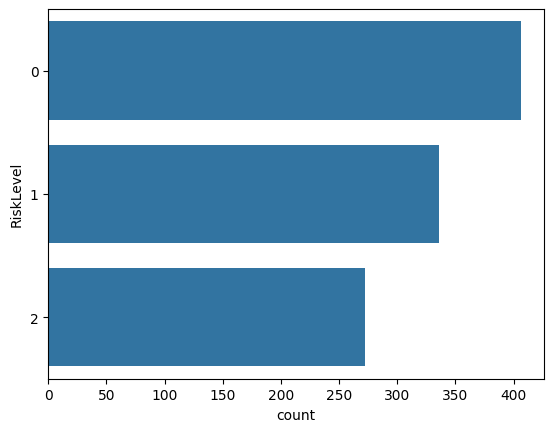

In [195]:
sns.countplot(y=dataset['RiskLevel'])

In [196]:
x=dataset.iloc[:,[0,1,2,3,4,5]].values

In [197]:
x[0]

array([ 25., 130.,  80.,  15.,  98.,  86.])

In [198]:
y=dataset.iloc[:,[6]].values

In [199]:
y[0]

array([2])

In [ ]:

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=45)

In [201]:
print(len(x_train), len(x_test), len(y_train)+ len(y_test))

709 305 1014


In [202]:
from sklearn.ensemble import RandomForestClassifier

model=RandomForestClassifier()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
score=model.score(x_test,y_test)
print("Random forest score is ",score*100)

d:\Maternal health risk\projectenv\lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random forest score is  83.27868852459017


In [203]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
score=model.score(x_test,y_test)
print("Random forest score is ",score*100)

Random forest score is  83.27868852459017


In [204]:
cm=confusion_matrix(y_test,y_pred)
print(cm)


[[93 17  3]
 [12 94 10]
 [ 4  5 67]]


In [205]:
cr=classification_report(y_test,y_pred)
print(cr)


              precision    recall  f1-score   support

           0       0.85      0.82      0.84       113
           1       0.81      0.81      0.81       116
           2       0.84      0.88      0.86        76

    accuracy                           0.83       305
   macro avg       0.83      0.84      0.84       305
weighted avg       0.83      0.83      0.83       305



In [206]:
joblib.dump(model,'model.pkl')

['model.pkl']